# SAD のラティスとコマンドを notebook に貼って実行する

SAD のラティスファイルとコマンドファイルの中身を、そのままセルに貼って実行します。セルの先頭に `%%sad` と書くだけで、セルの全体が SAD のコードとして渡るので、引用符やバックスラッシュを書き直す必要はありません。

- `%%sad lattice` : ラティスを保存する (実行しない。同じ名前のセルを再実行すると置き換わる)
- `%%sad` : 保存したラティスとこのセルを、最初から実行する (SAD の `gs ラティス コマンド` と同じ)
- `%%sad --continue` : 前の実行の状態の続きに、FFS の文を流す
- `sad.value('...')` : SAD の式の値を Python の値として取り出す

In [1]:
%load_ext pysad.notebook

## 1. ラティスを貼る

サンプルの FODO ring (`example/00_lattice/FODO_ring.sad`。24 セル、3 GeV、周長 105.6 m) の中身です。

In [2]:
%%sad lattice
MOMENTUM = 3GEV;
! FODO ring: 24 cells, 15 deg bend per cell (2*pi total), 3 GeV
DRIFT D1 = (L=1.0) D2 = (L=0.5) DS = (L=0.1);
QUAD  QF = (L=0.3 K1=0.7) QD = (L=0.3 K1=-0.6);
SEXT  SF = (L=0.2 K2=0) SD = (L=0.2 K2=0);
BEND  B  = (L=1.2 ANGLE=0.2617993877991494 E1=0.1308996938995747 E2=0.1308996938995747);
MARK  ORIGIN = ();
CAVI RF = (L=0 VOLT=1.5E6 FREQ=5.0E8 PHI=0);
LINE CELL = (SF DS QF D2 B D2 QD DS SD D1);
LINE RING = (ORIGIN RF 24*CELL);

(pysad) ラティス 'main' を保存しました (11 行。保存中: main)。コマンドは `%%sad` のセルに書きます


## 2. コマンドを貼って実行する

`!` で始まる行は SAD のコメントです (セルのマジックの本文は変換されずに SAD に届きます)。

In [3]:
%%sad
FFS;
! 周期ラティスとして光学を計算する
USE RING; CELL; CALC;
Print["NX=", Twiss["NX","$$$"], "  NY=", Twiss["NY","$$$"]];

pysad 2.5.3 -- a Python translation of SAD (Strategic Accelerator Design), K64 version. compat mode: v2
Based on SAD by K. Oide (KEK), K64 version: the physics and the SADScript language follow SAD.
SAD packages (*.n) bundled in this package are copied from the SAD source (KEK Accelerator Laboratory, BSD license; see pysad/sad_copy/README.md).
Source code: https://github.com/Ken-Harada1234/pysad
Examples, documentation, the physics guide and the tests are not in the pip package; see GitHub (https://github.com/Ken-Harada1234/pysad) and https://ken-harada1234.github.io/pysad/ (to hide this message: PYSAD_QUIET=1)


 Matched. (  0.000    ) DP = 0.01000  DP0 = 0.00000  ExponentOfResidual = 2.0  OffMomentumWeight =   1.000  CALEXP  


$$$       f AX    #######  #  -2.166305 $$$       f BX    #######  #   5.025185 $$$       f NX    #######  #   6.696329


$$$       f AY    #######  #   1.207630 $$$       f BY    #######  #   2.557661 $$$       f NY    #######  #   4.906056


$$$       f LENG  #######  #  105.60000


NX=42.07427561351298  NY=30.82565922589416


## 3. 結果を Python で使う

`sad.value()` は、数なら `float`、並びなら `list` を返します。ここでは全要素のベータ関数を取り出して描きます。

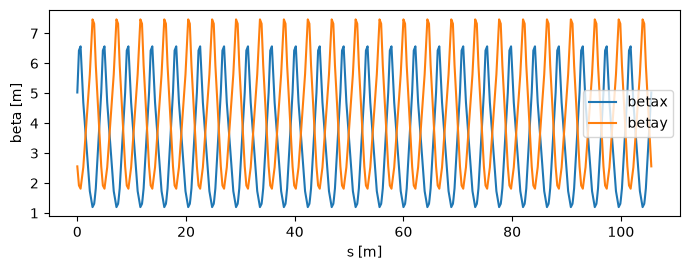

要素数 243  水平チューン 42.07427561351298


In [4]:
import matplotlib.pyplot as plt
s  = sad.value('Twiss["S","*"]')
bx = sad.value('Twiss["BX","*"]')
by = sad.value('Twiss["BY","*"]')
plt.figure(figsize=(7, 2.8))
plt.plot(s, bx, label='betax'); plt.plot(s, by, label='betay')
plt.xlabel('s [m]'); plt.ylabel('beta [m]'); plt.legend(); plt.tight_layout(); plt.show()
print('要素数', len(s), ' 水平チューン', sad.value('Twiss["NX","$$$"]'))

## 4. 続きを流す (`--continue`)

前の実行の状態のまま、四極の強さを変えて、もう一度計算します。要素・LINE の定義はここには書けません (新しい `%%sad` のセルに書きます)。

In [5]:
%%sad --continue
LINE["K1","QF"] = 0.75;
CALC;
Print["NX=", Twiss["NX","$$$"], "  NY=", Twiss["NY","$$$"]];

 Matched. (  0.000    ) DP = 0.01000  DP0 = 0.00000  ExponentOfResidual = 2.0  OffMomentumWeight =   1.000  CALEXP  


$$$       f AX    #######  #  -2.391694 $$$       f BX    #######  #   5.133427 $$$       f NX    #######  #   7.350804


$$$       f AY    #######  #   1.282281 $$$       f BY    #######  #   2.640538 $$$       f NY    #######  #   4.733093


$$$       f LENG  #######  #  105.60000


NX=46.18646188692837  NY=29.738899591761037


## 5. マジックを使わずに Python から書く

`pysad.run()` に文字列を渡します。`r'''...'''` の生文字列なら、引用符もバックスラッシュも、そのまま書けます。最初から実行し直します (保存したラティスは捨てます)。

In [6]:
import pysad
pysad.run(r'''
MOMENTUM = 3GEV;
DRIFT D1 = (L=1.0) D2 = (L=0.5);
QUAD  QF = (L=0.3 K1=0.7) QD = (L=0.3 K1=-0.6);
BEND  B  = (L=1.2 ANGLE=0.2617993877991494 E1=0.1308996938995747 E2=0.1308996938995747);
LINE CELL = (QF D2 B D2 QD D1);
LINE RING = (24*CELL);
FFS;
USE RING; CELL; CALC;
Print["NX=", Twiss["NX","$$$"]];
''', reset=True)

 Matched. (  0.000    ) DP = 0.01000  DP0 = 0.00000  ExponentOfResidual = 2.0  OffMomentumWeight =   1.000  CALEXP  


$$$       f AX    #######  #  -2.155769 $$$       f BX    #######  #   5.009353 $$$       f NX    #######  #   5.413516


$$$       f AY    #######  #   1.397232 $$$       f BY    #######  #   2.654699 $$$       f NY    #######  #   3.733745


$$$       f LENG  #######  #  91.200000


NX=34.01412233018365


<pysad.notebook.Session lattices=[], ran=True>